In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout, Reshape, Permute
import time #helper libraries
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
'''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
'''
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

2025-12-12 00:08:49.875256: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-12-12 00:08:49.886598: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-12-12 00:08:49.926057: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-12-12 00:08:49.926097: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-12-12 00:08:49.926129: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

"\nfor dirname, _, filenames in os.walk('/kaggle/input'):\n    for filename in filenames:\n        print(os.path.join(dirname, filename))\n"

In [2]:
df= pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")
score_cols = [f"scores_{i}" for i in range(23)]
df = df.drop(columns=score_cols)


In [3]:
df = df.sort_values(by="timestamp").reset_index(drop=True)


In [4]:
df

,timestamp,symbol,open,high,low,close,volume,sma_10,sma_50,ema_20,...,sum_of_scores,avg_of_scores,normalized_avg,max_of_scores,min_of_scores,normalized_min,normalized_max,avg_score_of_normalized_min,avg_score_of_normalized_max,avg_score_of_normalized_avg
0,2023-01-03 09:00:00,TSLA,120.02,121.23,115.94,118.52,1306706,118.5200,118.5200,118.520000,...,"[-7, 2, 7, 1, -2, 5, 2, 0, 1, 5]","[-3.5, 1.0, 3.5, 0.5, -1.0, 2.5, 1.0, 0.0, 0.5...","[-0.7, 0.2, 0.7, 0.1, -0.2, 0.5, 0.2, 0.0, 0.1...","[-3, 1, 5, 4, 0, 5, 3, 1, 1, 3]","[-4, 1, 2, -3, -2, 0, -1, -1, 0, 2]","[-0.8, 0.2, 0.4, -0.6, -0.4, 0.0, -0.2, -0.2, ...","[-0.6, 0.2, 1.0, 0.8, 0.0, 1.0, 0.6, 0.2, 0.2,...",-0.12,0.40,0.140000
1,2023-01-03 10:00:00,TSLA,118.53,120.50,118.20,120.38,568635,119.4500,119.4500,118.697143,...,"[2, 5, 0, 3, -1, 4, 0, -2, -2, 4]","[2.0, 5.0, 0.0, 3.0, -1.0, 4.0, 0.0, -2.0, -2....","[0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....","[2, 5, 0, 3, -1, 4, 0, -2, -2, 4]","[2, 5, 0, 3, -1, 4, 0, -2, -2, 4]","[0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....","[0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....",0.26,0.26,0.260000
2,2023-01-03 11:00:00,TSLA,120.28,120.50,117.95,118.61,547403,119.1700,119.1700,118.688844,...,"[-18, 14, 10, 10, 2, 11, -2, 15, -7, -7]","[-3.0, 2.3333333333333335, 1.6666666666666667,...","[-0.6, 0.4666666666666667, 0.33333333333333337...","[-2, 5, 4, 5, 1, 5, 3, 6, 1, 2]","[-5, 0, 0, -2, -1, -1, -4, 0, -5, -5]","[-1.0, 0.0, 0.0, -0.4, -0.2, -0.2, -0.8, 0.0, ...","[-0.4, 1.0, 0.8, 1.0, 0.2, 1.0, 0.6, 1.2, 0.2,...",-0.46,0.60,0.093333
3,2023-01-03 12:00:00,TSLA,118.63,118.99,116.61,118.28,1529445,118.9475,118.9475,118.649906,...,"[-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]","[-4.0, 0.0, 3.0, -1.0, -5.0, 0.0, 0.0, -2.0, -...","[-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...","[-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]","[-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]","[-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...","[-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...",-0.24,-0.24,-0.240000
4,2023-01-03 13:00:00,TSLA,118.32,121.90,116.61,118.93,2886437,118.9440,118.9440,118.676582,...,"[-20, 2, 19, 16, 6, 16, 4, 5, -2, 9]","[-2.5, 0.25, 2.375, 2.0, 0.75, 2.0, 0.5, 0.625...","[-0.5, 0.05, 0.475, 0.4, 0.15, 0.4, 0.1, 0.125...","[0, 2, 5, 4, 5, 5, 3, 3, 2, 5]","[-5, -4, 0, -4, -5, -2, -2, -3, -5, -1]","[-1.0, -0.8, 0.0, -0.8, -1.0, -0.4, -0.4, -0.6...","[0.0, 0.4, 1.0, 0.8, 1.0, 1.0, 0.6, 0.6, 0.4, ...",-0.62,0.68,0.137500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1032,2023-12-08 13:00:00,TSLA,242.19,243.37,239.75,240.40,1406899,242.3970,241.1094,241.760952,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.00,0.00,0.000000
1033,2023-12-08 14:00:00,TSLA,240.46,243.65,239.27,242.40,15237079,242.3730,241.2916,241.821814,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.00,0.00,0.000000
1034,2023-12-08 15:00:00,TSLA,242.40,245.23,242.40,245.19,22432349,242.6320,241.5218,242.142593,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.00,0.00,0.000000
1035,2023-12-08 16:00:00,TSLA,245.19,245.27,241.67,241.97,15853691,242.5470,241.5982,242.126156,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0,

In [5]:
df['close_sign'] = (df['close'] > df['close'].shift(1)).astype(int)
df['close_diff'] = (df['close'].diff()).astype(float)


In [6]:
df['close_sign']

0       0
1       1
2       0
3       0
4       1
       ..
1032    0
1033    1
1034    1
1035    0
1036    0
Name: close_sign, Length: 1037, dtype: int64

# LSTM

## close price only

In [7]:
def create_dataset(dataset, look_back=1):
	dataX, dataY = [], []
	for i in range(len(dataset)-look_back-1):
		a = dataset[i:(i+look_back), 0]
		dataX.append(a)
		dataY.append(dataset[i + look_back, 0])
	return np.array(dataX), np.array(dataY)

In [8]:
np.random.seed(5)


In [9]:
# take close price column[5]
all_y = df["close_sign"].values
dataset=all_y.reshape(-1, 1)


In [10]:
# normalize the dataset
#scaler = MinMaxScaler(feature_range=(0, 1))
#dataset = scaler.fit_transform(dataset)

In [11]:
# split into train and test sets, 50% test data, 50% training data
train_size = int(len(dataset) * 0.7)
test_size = len(dataset) - train_size
train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]

In [12]:
look_back = 15
trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

In [13]:

# reshape input to be [samples, time steps, features]
trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1))
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

# create and fit the LSTM network, optimizer=adam, 25 neurons, dropout 0.1
model = Sequential()
model.add(LSTM(25, input_shape=(look_back, 1)))
model.add(Dropout(0.1))
model.add(Dense(1, activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(trainX, trainY, epochs=1000, batch_size=240, verbose=1)

2025-12-12 00:09:23.345567: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Epoch 1/1000
3/3 [==============================] - 2s 9ms/step - loss: 0.6943 - accuracy: 0.5106
Epoch 2/1000
3/3 [==============================] - 0s 8ms/step - loss: 0.6938 - accuracy: 0.4965
Epoch 3/1000
3/3 [==============================] - 0s 8ms/step - loss: 0.6930 - accuracy: 0.4951
Epoch 4/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6934 - accuracy: 0.5233
Epoch 5/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6932 - accuracy: 0.4866
Epoch 6/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6914 - accuracy: 0.5416
Epoch 7/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6922 - accuracy: 0.5275
Epoch 8/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6923 - accuracy: 0.5063
Epoch 9/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6920 - accuracy: 0.5233
Epoch 10/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6926 - accuracy: 0.4852
Epoch 11/1000
3/3 [

3/3 [==============================] - 0s 6ms/step - loss: 0.6898 - accuracy: 0.5346
Epoch 84/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6894 - accuracy: 0.5317
Epoch 85/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6882 - accuracy: 0.5261
Epoch 86/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6902 - accuracy: 0.5388
Epoch 87/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6898 - accuracy: 0.5416
Epoch 88/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6894 - accuracy: 0.5416
Epoch 89/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.6896 - accuracy: 0.5233
Epoch 90/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6910 - accuracy: 0.5233
Epoch 91/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6895 - accuracy: 0.5261
Epoch 92/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6884 - accuracy: 0.5501
Epoch 93/1000
3/3 [=====

3/3 [==============================] - 0s 7ms/step - loss: 0.6804 - accuracy: 0.5557
Epoch 166/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6791 - accuracy: 0.5684
Epoch 167/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6801 - accuracy: 0.5614
Epoch 168/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6787 - accuracy: 0.5853
Epoch 169/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6799 - accuracy: 0.5726
Epoch 170/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6787 - accuracy: 0.5684
Epoch 171/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6782 - accuracy: 0.5755
Epoch 172/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6808 - accuracy: 0.5670
Epoch 173/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6807 - accuracy: 0.5698
Epoch 174/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6818 - accuracy: 0.5557
Epoch 175/1000


3/3 [==============================] - 0s 7ms/step - loss: 0.6735 - accuracy: 0.5839
Epoch 248/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6750 - accuracy: 0.5839
Epoch 249/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6714 - accuracy: 0.5740
Epoch 250/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6729 - accuracy: 0.5839
Epoch 251/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6739 - accuracy: 0.5712
Epoch 252/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6701 - accuracy: 0.5797
Epoch 253/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6741 - accuracy: 0.5712
Epoch 254/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6695 - accuracy: 0.5811
Epoch 255/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6721 - accuracy: 0.5980
Epoch 256/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6686 - accuracy: 0.5896
Epoch 257/1000


3/3 [==============================] - 0s 7ms/step - loss: 0.6631 - accuracy: 0.6192
Epoch 330/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6652 - accuracy: 0.6178
Epoch 331/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6656 - accuracy: 0.6023
Epoch 332/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6641 - accuracy: 0.6107
Epoch 333/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6636 - accuracy: 0.5994
Epoch 334/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6634 - accuracy: 0.6079
Epoch 335/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6617 - accuracy: 0.6164
Epoch 336/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6650 - accuracy: 0.5938
Epoch 337/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6650 - accuracy: 0.6008
Epoch 338/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6649 - accuracy: 0.6121
Epoch 339/1000


... (4 outputs left out)

3/3 [==============================] - 0s 7ms/step - loss: 0.6154 - accuracy: 0.6333
Epoch 740/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6103 - accuracy: 0.6516
Epoch 741/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6149 - accuracy: 0.6629
Epoch 742/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6079 - accuracy: 0.6516
Epoch 743/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6084 - accuracy: 0.6685
Epoch 744/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6117 - accuracy: 0.6417
Epoch 745/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6111 - accuracy: 0.6643
Epoch 746/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6095 - accuracy: 0.6587
Epoch 747/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6163 - accuracy: 0.6375
Epoch 748/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6008 - accuracy: 0.6573
Epoch 749/1000


3/3 [==============================] - 0s 7ms/step - loss: 0.5860 - accuracy: 0.6855
Epoch 822/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5835 - accuracy: 0.6728
Epoch 823/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5963 - accuracy: 0.6770
Epoch 824/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5828 - accuracy: 0.6770
Epoch 825/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.5822 - accuracy: 0.6742
Epoch 826/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5907 - accuracy: 0.6770
Epoch 827/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5843 - accuracy: 0.6742
Epoch 828/1000
3/3 [==============================] - 0s 8ms/step - loss: 0.5884 - accuracy: 0.6615
Epoch 829/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5830 - accuracy: 0.6827
Epoch 830/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5921 - accuracy: 0.6629
Epoch 831/1000

3/3 [==============================] - 0s 7ms/step - loss: 0.5701 - accuracy: 0.6996
Epoch 904/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5743 - accuracy: 0.6827
Epoch 905/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5758 - accuracy: 0.6855
Epoch 906/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5709 - accuracy: 0.6841
Epoch 907/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5684 - accuracy: 0.7010
Epoch 908/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5702 - accuracy: 0.6855
Epoch 909/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5702 - accuracy: 0.6968
Epoch 910/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5686 - accuracy: 0.6925
Epoch 911/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5621 - accuracy: 0.6798
Epoch 912/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5624 - accuracy: 0.6897
Epoch 913/1000


3/3 [==============================] - 0s 7ms/step - loss: 0.5363 - accuracy: 0.7179
Epoch 986/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5541 - accuracy: 0.7123
Epoch 987/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5537 - accuracy: 0.6982
Epoch 988/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5433 - accuracy: 0.7137
Epoch 989/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5555 - accuracy: 0.7052
Epoch 990/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5446 - accuracy: 0.7221
Epoch 991/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5499 - accuracy: 0.7207
Epoch 992/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5441 - accuracy: 0.7193
Epoch 993/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5496 - accuracy: 0.7024
Epoch 994/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.5477 - accuracy: 0.7207
Epoch 995/1000


10/10 [==============================] - 0s 1ms/step
trainPredict::  (709, 1)
testPredict::  (296, 1)
Train Accuracy: 0.7334273624823695
Test Accuracy: 0.47297297297297297
Classification Report (Test):
              precision    recall  f1-score   support

           0       0.45      0.41      0.43       142
           1       0.49      0.53      0.51       154

    accuracy                           0.47       296
   macro avg       0.47      0.47      0.47       296
weighted avg       0.47      0.47      0.47       296



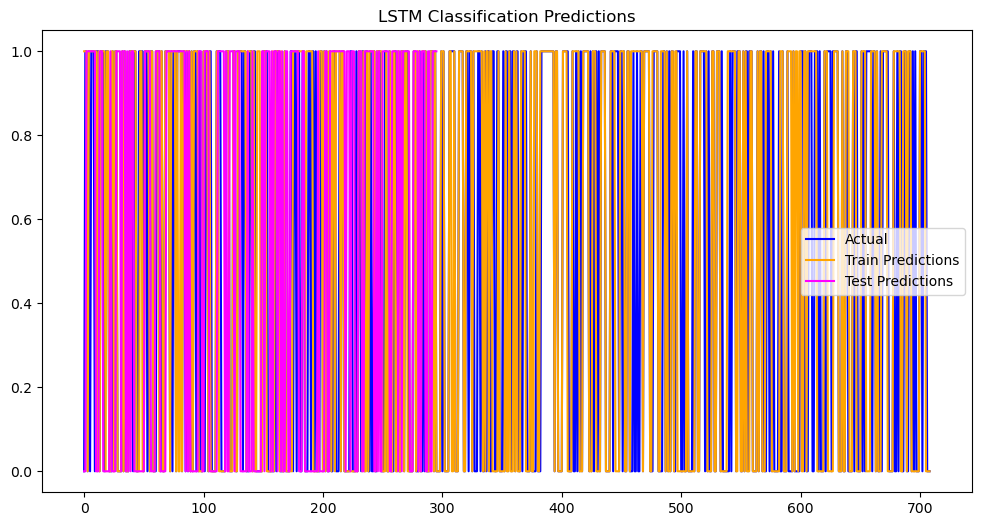

In [14]:
# make predictions
trainPredict = model.predict(trainX)
testPredict = model.predict(testX)
print("trainPredict:: ", trainPredict.shape)
print("testPredict:: ", testPredict.shape)


# Convert continuous labels to 0/1 using the same threshold as predictions
threshold = 0.5  # or whatever makes sense for your data
trainY_class = (trainY > threshold).astype(int).reshape(-1)
testY_class = (testY > threshold).astype(int).reshape(-1)

trainPredClass = (trainPredict > threshold).astype(int).reshape(-1)
testPredClass = (testPredict > threshold).astype(int).reshape(-1)

from sklearn.metrics import accuracy_score, classification_report

print("Train Accuracy:", accuracy_score(trainY_class, trainPredClass))
print("Test Accuracy:", accuracy_score(testY_class, testPredClass))
print("Classification Report (Test):")
print(classification_report(testY_class, testPredClass))


# export prediction and actual prices
#df = pd.DataFrame(data={"prediction": np.around(list(testPredict.reshape(-1)), decimals=2), "test_price": np.around(list(testPrices.reshape(-1)), decimals=2)})
#df.to_csv("lstm_result.csv", sep=';', index=None)

# plot the actual price, prediction in test data=red line, actual price=blue line
#plt.plot(testPredictPlot)
#plt.show()

plt.figure(figsize=(12,6))
plt.plot(trainY, label="Actual", color="blue")
plt.plot(trainPredClass, label="Train Predictions", color="orange")
plt.plot(testPredClass, label="Test Predictions", color="magenta")
plt.legend()
plt.title("LSTM Classification Predictions")
plt.show()


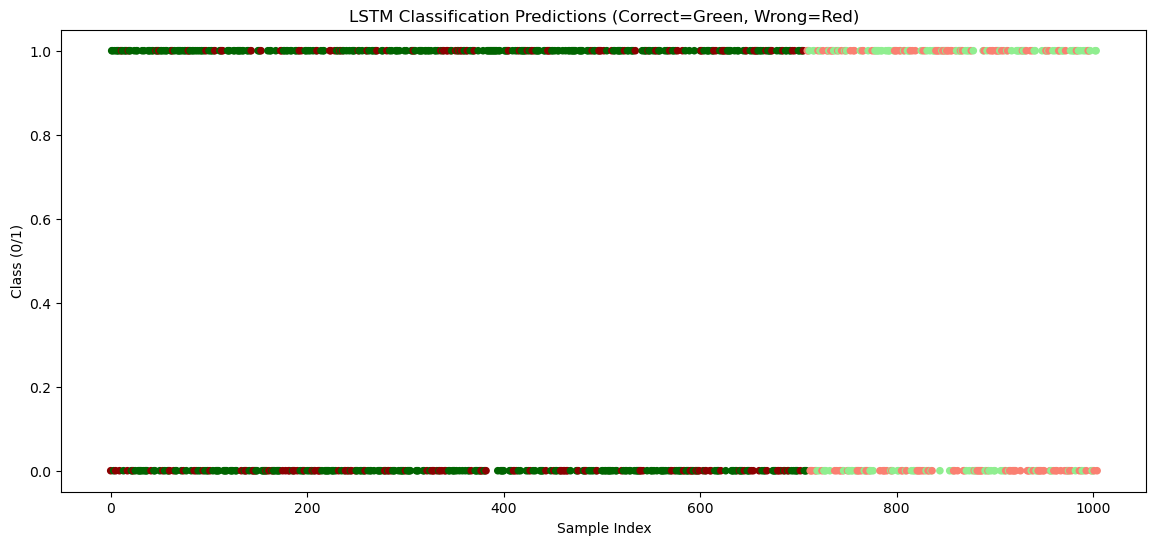

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Flatten arrays
actual = trainY_class.tolist() + testY_class.tolist()
pred_train = trainPredClass
pred_test = testPredClass

# Combine predictions and labels for plotting
predictions = np.concatenate([pred_train, pred_test])
is_train = np.array([True]*len(pred_train) + [False]*len(pred_test))

# Colors: green if correct, red if wrong; two shades for train/test
colors = []
for i, (a, p, t) in enumerate(zip(actual, predictions, is_train)):
    if a == p:
        colors.append('darkgreen' if t else 'lightgreen')
    else:
        colors.append('darkred' if t else 'salmon')

plt.figure(figsize=(14,6))
plt.scatter(range(len(actual)), actual, c=colors, s=20)
plt.xlabel("Sample Index")
plt.ylabel("Class (0/1)")
plt.title("LSTM Classification Predictions (Correct=Green, Wrong=Red)")
plt.show()


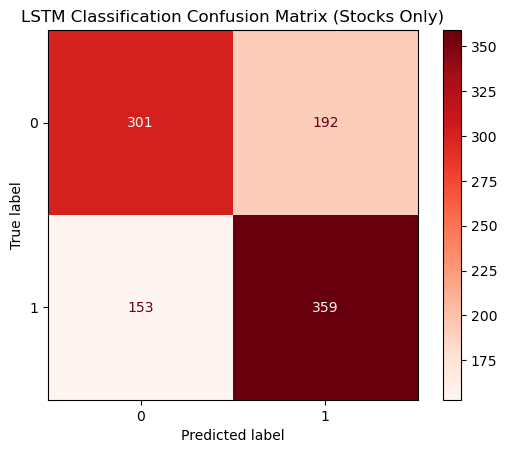

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Combine train and test if you want overall
y_true = np.concatenate([trainY_class, testY_class])
y_pred = np.concatenate([trainPredClass, testPredClass])

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Reds)
plt.title("LSTM Classification Confusion Matrix (Stocks Only)")
plt.show()


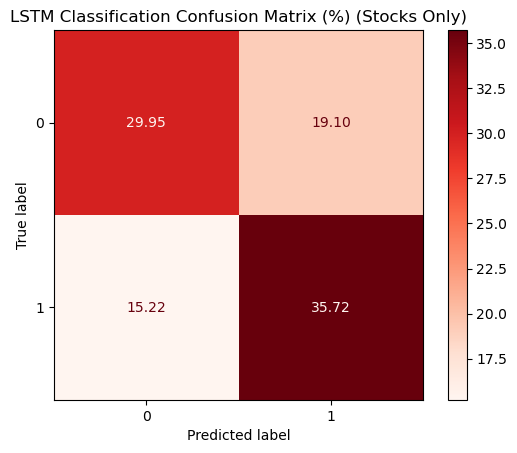

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

# Combine train and test if you want overall
y_true = np.concatenate([trainY_class, testY_class])
y_pred = np.concatenate([trainPredClass, testPredClass])

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Convert to percentages
cm_percent = cm.astype('float') / cm.sum() * 100

# Display
disp = ConfusionMatrixDisplay(confusion_matrix=cm_percent, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Reds, values_format=".2f")  # format as 2 decimal percentages
plt.title("LSTM Classification Confusion Matrix (%) (Stocks Only)")
plt.show()


In [18]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_true, y_pred)
print(f"Total Accuracy: {accuracy*100:.2f}%")


Total Accuracy: 65.67%


# Version 2: split then scale

https://machinelearningmastery.com/time-series-forecasting-long-short-term-memory-network-python/

In [19]:
from pandas import DataFrame
from pandas import Series
from pandas import concat
from pandas import read_csv
from datetime import datetime

from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from math import sqrt
from matplotlib import pyplot
import numpy


In [20]:
# date-time parsing function for loading the dataset
def parser(x):
	return datetime.strptime('190'+x, '%Y-%m')

In [21]:
# frame a sequence as a supervised learning problem
lookback = 30
def timeseries_to_supervised(data, lag=lookback):
	df = DataFrame(data)
	columns = [df.shift(i) for i in range(1, lag+1)]
	columns.append(df)
	df = concat(columns, axis=1)
	df.fillna(0, inplace=True)
	return df


# create a differenced series
def difference(dataset, interval=1):
	diff = list()
	for i in range(interval, len(dataset)):
		value = dataset[i] - dataset[i - interval]
		diff.append(value)
	return Series(diff)

In [22]:
df2 = timeseries_to_supervised(df, lag=lookback)

In [23]:
df.shape

(1037, 30)

In [24]:
df2.shape

(1037, 930)

In [25]:
#df2["avg_score_of_normalized_min"]

In [26]:

# invert differenced value
def inverse_difference(history, yhat, interval=1):
	return yhat + history[-interval]

# scale train and test data to [-1, 1]
def scale(train, test):
	# fit scaler
	scaler = MinMaxScaler(feature_range=(-1, 1))
	scaler = scaler.fit(train)
	# transform train
	train = train.reshape(train.shape[0], train.shape[1])
	train_scaled = scaler.transform(train)
	# transform test
	test = test.reshape(test.shape[0], test.shape[1])
	test_scaled = scaler.transform(test)
	return scaler, train_scaled, test_scaled

# inverse scaling for a forecasted value
def invert_scale(scaler, X, value):
	new_row = [x for x in X] + [value]
	array = numpy.array(new_row)
	array = array.reshape(1, len(array))
	inverted = scaler.inverse_transform(array)
	return inverted[0, -1]


In [27]:

# fit an LSTM network to training data
def fit_lstm(train, batch_size, nb_epoch, neurons):
	X, y = train[:, 0:-1], train[:, -1]
	X = X.reshape(X.shape[0], 1, X.shape[1])
	model = Sequential()
	model.add(LSTM(neurons, batch_input_shape=(batch_size, X.shape[1], X.shape[2]), stateful=True))
	model.add(Dense(1))
	model.compile(loss='mean_squared_error', optimizer='adam')
	for i in range(nb_epoch):
		model.fit(X, y, epochs=1, batch_size=batch_size, verbose=0, shuffle=False)
		model.reset_states()
	return model

# make a one-step forecast
def forecast_lstm(model, batch_size, X):
	X = X.reshape(1, 1, len(X))
	yhat = model.predict(X, batch_size=batch_size)
	return yhat[0,0]

In [28]:
df.dtypes[df.dtypes == 'object']


timestamp         object
symbol            object
day               object
sum_of_scores     object
avg_of_scores     object
normalized_avg    object
max_of_scores     object
min_of_scores     object
normalized_min    object
normalized_max    object
dtype: object

In [29]:
df = df.apply(pd.to_numeric, errors='coerce')
df = df.fillna(0)

raw_values = df.values.astype(float)
diff_values = difference(raw_values, 1)


In [30]:
# transform data to be supervised learning
supervised = timeseries_to_supervised(diff_values, 1)
supervised_values = supervised.values

# split data into train and test-sets
train, test = supervised_values[0:-500], supervised_values[-500:]



In [31]:
# transform the scale of the data
scaler, train_scaled, test_scaled = scale(train, test)

ValueError: setting an array element with a sequence.

In [ ]:


# repeat experiment
repeats = 30
error_scores = list()
for r in range(repeats):
	# fit the model
	lstm_model = fit_lstm(train_scaled, 1, 3000, 4)
	# forecast the entire training dataset to build up state for forecasting
	train_reshaped = train_scaled[:, 0].reshape(len(train_scaled), 1, 1)
	lstm_model.predict(train_reshaped, batch_size=1)
	# walk-forward validation on the test data
	predictions = list()
	for i in range(len(test_scaled)):
		# make one-step forecast
		X, y = test_scaled[i, 0:-1], test_scaled[i, -1]
		yhat = forecast_lstm(lstm_model, 1, X)
		# invert scaling
		yhat = invert_scale(scaler, X, yhat)
		# invert differencing
		yhat = inverse_difference(raw_values, yhat, len(test_scaled)+1-i)
		# store forecast
		predictions.append(yhat)
	# report performance
	rmse = sqrt(mean_squared_error(raw_values[-12:], predictions))
	print('%d) Test RMSE: %.3f' % (r+1, rmse))
	error_scores.append(rmse)

# summarize results
results = DataFrame()
results['rmse'] = error_scores
print(results.describe())
results.boxplot()
pyplot.show()